In [1]:
import os, uuid, hashlib, platform
# 1.填写学号（字符串！）
STUDENT_ID = "20244080112"

# 2.打印 conda 环境
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

# 3.机器指纹
MACHINE_FP = hashlib.sha256((
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}"
).encode()).hexdigest()[:16]

# 4.生成唯一ID
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"

print(f"[学号]      {STUDENT_ID}")
print(f"[机器指纹]  {MACHINE_FP}")
print(f"[RUN_ID]    {RUN_ID}")

[Conda 环境] base
[学号]      20244080112
[机器指纹]  ffbafa4ebf03ea2f
[RUN_ID]    20244080112-ffbafa4ebf03ea2f


In [11]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


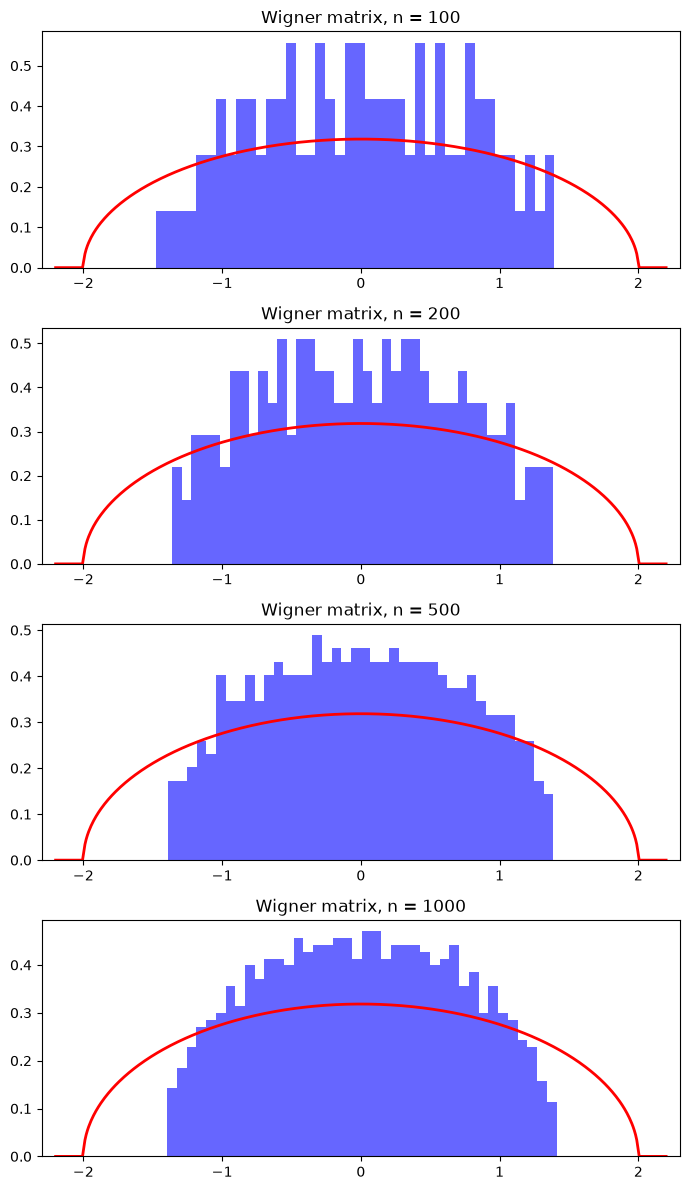

In [12]:
def wigner_density(x):
    if np.abs(x) > 2:
        return 0.0
    return (1 / (2 * np.pi)) * np.sqrt(4 - x ** 2)

def generate_wigner(n):
    if not isinstance(n, int) or n <= 0:
        raise ValueError("n 必须是正整数")
    # 均值0，方差 1/n
    mat = np.random.normal(loc=0, scale=np.sqrt(1 / n), size=(n, n))
    mat = (mat + mat.T) / 2
    return mat

def get_spectrum(matrix):
    eigvals = np.linalg.eigvalsh(matrix)
    eigvals = np.sort(eigvals)[::-1]
    return eigvals

fig, axes = plt.subplots(4, 1, figsize=(7, 12))
ns = [100, 200, 500, 1000]

for ax, n in zip(axes, ns):
    Z = generate_wigner(n)
    evs = get_spectrum(Z)
    ax.hist(evs, bins=40, density=True, color="blue", alpha=0.6)
    x_line = np.linspace(-2.2, 2.2, 500)
    y_line = np.vectorize(wigner_density)(x_line)
    ax.plot(x_line, y_line, c="red", lw=2)
    ax.set_title(f"Wigner matrix, n = {n}")
    ax.set_xlim(-2.3, 2.3)

plt.tight_layout()
plt.show()


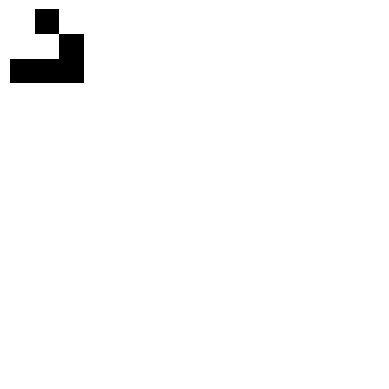

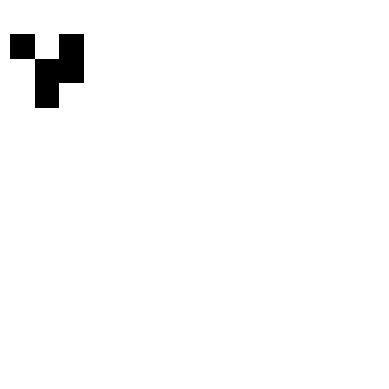

In [15]:
def is_valid_board(board):
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    unique = np.unique(board)
    return set(unique).issubset({0, 1})

def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("不是合法生命游戏棋盘")
    m, n = board.shape
    next_board = np.zeros_like(board)
    # 八个方向偏移
    dirs = [(-1,-1),(-1,0),(-1,1),
            (0,-1),          (0,1),
            (1,-1), (1,0), (1,1)]
    for i in range(m):
        for j in range(n):
            cnt = 0
            for di, dj in dirs:
                ni = (i + di) % m
                nj = (j + dj) % n
                cnt += board[ni, nj]
            if board[i, j] == 1:
                if cnt == 2 or cnt == 3:
                    next_board[i, j] = 1
                else:
                    next_board[i, j] = 0
            else:
                if cnt == 3:
                    next_board[i, j] = 1
    return next_board

def draw_gol_board(board):
    plt.imshow(board, cmap="gray_r")
    plt.xticks([])
    plt.yticks([])
    plt.axis("off")
    plt.show()

# 滑翔机测试
test = np.zeros((15,15))
test[0,1] = 1
test[1,2] = 1
test[2,0] = 1
test[2,1] = 1
test[2,2] = 1
draw_gol_board(test)
newb = gol_step(test)
draw_gol_board(newb)


In [19]:
import pandas as pd
from sklearn.datasets import load_iris

# 加载鸢尾花数据集，不需要本地 csv
iris = load_iris()
df = pd.DataFrame(data=iris.data, columns=["sepal_length", "sepal_width", "petal_length", "petal_width"])
df["species"] = [iris.target_names[i] for i in iris.target]

print("数据点数量：", len(df))
print("\n各列类型：")
print(df.dtypes)
print("\n列名：")
print(df.columns.tolist())

print("\n花卉种类：")
species_unique = df["species"].unique()
print(species_unique)
print("种类数目：", len(species_unique))

# 修改指定行
df.iloc[34] = [4.9, 3.1, 1.5, 0.2, "setosa"]
df.iloc[37] = [4.9, 3.6, 1.4, 0.1, "setosa"]

print("修改后的第 34 行：")
print(df.iloc[34])
print("\n修改后的第 37 行：")
print(df.iloc[37])

# 生成比例列
df["Petal.Ratio"] = df["petal_length"] / df["petal_width"]
df["Sepal.Ratio"] = df["sepal_length"] / df["sepal_width"]

# 导出文件
df.to_csv("iris_corrected.csv", index=False)

# 分组聚合
agg_result = df.groupby("species")[["Petal.Ratio", "Sepal.Ratio"]].agg(
    ["mean", "median", "min", "max", "std"]
)
print(agg_result)


数据点数量： 150

各列类型：
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object

列名：
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

花卉种类：
<StringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str
种类数目： 3
修改后的第 34 行：
sepal_length       4.9
sepal_width        3.1
petal_length       1.5
petal_width        0.2
species         setosa
Name: 34, dtype: object

修改后的第 37 行：
sepal_length       4.9
sepal_width        3.6
petal_length       1.4
petal_width        0.1
species         setosa
Name: 37, dtype: object
           Petal.Ratio                                     Sepal.Ratio  \
                  mean    median       min   max       std        mean   
species                                                                  
setosa        6.908000  7.000000  2.666667  15.0  2.854545    1.470188   
versicolor    3.242837  3.240385  2.666667   4.1  0.312456    2.160402   
virgini